# 03 - Regression arena (California Housing)
All numbers are loaded from CSVs produced by `scripts/run_regression.py` (5 seeds, same split for every model within a seed, inner 3-fold CV tuning on train only).

In [1]:
import sys; sys.path.insert(0, '../src')
import pandas as pd, matplotlib.pyplot as plt
from arena.config import RAW_DIR, SUMMARY_DIR, PRED_DIR
from arena.viz import leaderboard_bar
pd.set_option('display.width', 160)

In [2]:
raw = pd.read_csv(RAW_DIR / 'reg_baseline.csv')
lb = pd.read_csv(SUMMARY_DIR / 'leaderboard_reg.csv')
print(raw.seed.nunique(), 'seeds,', raw.model.nunique(), 'models')

5 seeds, 6 models


## Leaderboard (mean over seeds, with std)

In [3]:
wide = lb.pivot(index='model', columns='metric', values='mean')[['rmse', 'mae', 'r2']].sort_values('rmse', ascending=True)
std = lb.pivot(index='model', columns='metric', values='std')[['rmse', 'mae', 'r2']]
wide.round(4)

metric,rmse,mae,r2
model,,,
xgb,0.4492,0.2927,0.8468
gb,0.4651,0.3087,0.8358
rf,0.5028,0.3272,0.8080
dt,0.5978,0.3983,0.7285
lin,0.7291,0.5333,0.5964
dummy,1.1479,0.9083,-0.0004


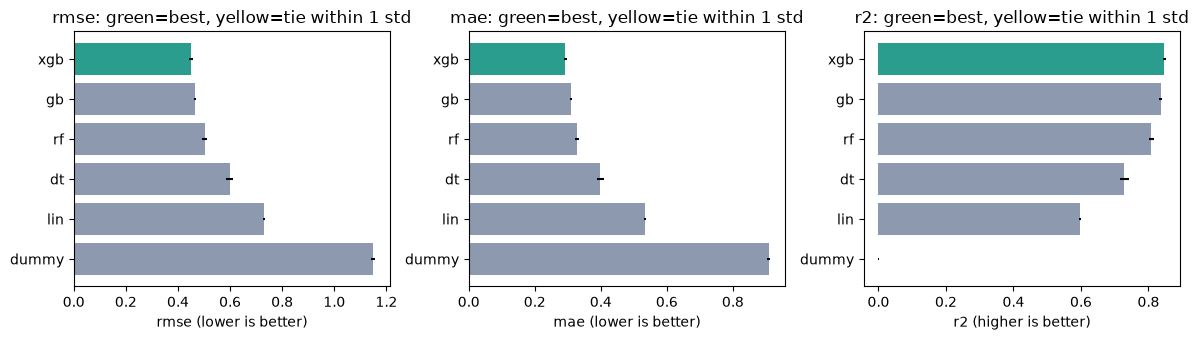

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, m in zip(axes, ['rmse', 'mae', 'r2']):
    leaderboard_bar(lb, m, ax)
plt.tight_layout()

## Best model per metric (with tie flag: a gap smaller than the leader's std is not a real win)

In [5]:
lb[lb.is_best | lb.tie_with_best][['metric','model','mean','std','is_best','tie_with_best']].round(4)

,metric,model,mean,std,is_best,tie_with_best
0,mae,xgb,0.2927,0.0043,True,False
6,r2,xgb,0.8468,0.0041,True,False
12,rmse,xgb,0.4492,0.0077,True,False


## Cost: fit time (tuning included)

In [6]:
lb.drop_duplicates('model')[['model','fit_time_s']].sort_values('fit_time_s').round(2)

,model,fit_time_s
4,lin,0.01
5,dummy,0.01
3,dt,0.83
0,xgb,2.71
2,rf,13.35
1,gb,51.62


## Tuned hyperparameters chosen (last seed shown)

In [7]:
raw[(raw.metric=='rmse') & (raw.seed==raw.seed.max())][['model','best_params']]

,model,best_params
73,dummy,{}
76,lin,{}
79,dt,"{""max_depth"": null, ""min_samples_leaf"": 20}"
82,rf,"{""max_depth"": null, ""min_samples_leaf"": 1}"
85,gb,"{""learning_rate"": 0.1, ""max_depth"": 5}"
88,xgb,"{""learning_rate"": 0.1, ""max_depth"": 6}"


**Reading the table:** RMSE/MAE are errors (lower is better). Targets are capped at 5.0, so every model under-predicts the most expensive houses; this is examined in the Failure Investigator.